In [ ]:
import xarray as xr
# import matplotlib as plt
from matplotlib import pyplot as plt
import pandas as pd
import geopandas as gpd
from sklearn import linear_model
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import mean_squared_error, mean_absolute_error
from math import sqrt
import seaborn as sns
import numpy as np

#Choose whether to save plots
save_plots = True

#Choose whether to threshold by number of sensors
toggle_threshold = True 

#threshold min number of stations required per pixel
sensor_threshold = 2

# Change the matplotlib dpi to increase or decrease output size in vscode
plt.rcParams['figure.dpi'] = 150 

# Change some of the default xarray settings
xr.set_options(keep_attrs=True, display_expand_data=False)

# EPSG to be used when setting coordinate reference systems
epsg = 4326 

# Function used for coercing clarity lat/lon to match the 0.2 x 0.2deg grid of TEMPO
# Note: I included the bias term (0.01) to force the lat/lon to match TEMPO lat/lon
def round_002(x):
    out = 0.02*round(x/0.02) + 0.01
    return out

def rmse(x,y):
    out = sqrt(mean_squared_error(x,y))
    return out

def savefig(name):
    fig_path = "/home/nlring/Documents/01_Research/larc-chicago-haq/figures/"
    if toggle_threshold == False:
        fig_name = fig_path + "/no-threshold/" + name
    else:
        fig_name = fig_path + name
    if save_plots == True:
        return plt.savefig(fig_name)


#define the paths for the hourly and time-of-day datasets.
hourly_dat_path  = "~/Documents/01_Research/larc-chicago-haq/datasets/clarity-tempo-hourly.nc"
diurnal_dat_path  = "~/Documents/01_Research/larc-chicago-haq/datasets/clarity-tempo-diurnal.nc"
nowinter_dat_path  = "~/Documents/01_Research/larc-chicago-haq/datasets/clarity-tempo-nowinter-diurnal.nc"

#load full data
ct_hourly_full = xr.open_dataset(hourly_dat_path)
ct_diurnal_full = xr.open_dataset(diurnal_dat_path)
ct_nowinter_full = xr.open_dataset(nowinter_dat_path)

#subset and filter pixel by sensor count.
if toggle_threshold == True:
    ct_hourly = ct_hourly_full.where(ct_hourly_full.sensor_count >= sensor_threshold)
    ct_diurnal = ct_diurnal_full.where(ct_diurnal_full.sensor_count >= sensor_threshold)
    ct_nowinter = ct_nowinter_full.where(ct_nowinter_full.sensor_count >= sensor_threshold)
else:
    ct_hourly = ct_hourly_full
    ct_diurnal = ct_diurnal_full
    ct_nowinter = ct_nowinter_full



#load full data
print(ct_hourly)
print(ct_diurnal)

<xarray.Dataset> Size: 1GB
Dimensions:            (time: 6493, latitude: 58, longitude: 52)
Coordinates:
  * time               (time) datetime64[ns] 52kB 2025-09-04T11:00:00 ... 202...
  * latitude           (latitude) float32 232B 41.27 41.29 41.31 ... 42.39 42.41
  * longitude          (longitude) float32 208B -88.25 -88.23 ... -87.25 -87.23
Data variables:
    sfc_no2_mean       (time, latitude, longitude) float64 157MB ...
    sfc_no2_median     (time, latitude, longitude) float64 157MB ...
    sfc_no2_var        (time, latitude, longitude) float64 157MB ...
    sfc_no2_sd         (time, latitude, longitude) float64 157MB ...
    sensor_count       (time, latitude, longitude) float64 157MB ...
    column_no2_mean    (time, latitude, longitude) float64 157MB ...
    column_no2_median  (time, latitude, longitude) float64 157MB ...
    column_no2_sd      (time, latitude, longitude) float64 157MB ...
    column_no2_var     (time, latitude, longitude) float64 157MB ...
<xarray.Dataset>

## Basic Linear Model
Here we apply a basic linear model to all data for the study period.

Coef:  3.6470501969698923e-16
Rank:  1.0
Intercept:  11.51067056236493
0.06472136894959324
                    time   latitude  longitude  sfc_no2_mean  column_no2_mean  \
4039 2025-09-04 12:00:00  41.650002 -87.550003     10.151250     4.081628e+15   
4087 2025-09-04 12:00:00  41.669998 -87.629997     15.822500     4.954445e+15   
4088 2025-09-04 12:00:00  41.669998 -87.610001     10.762500     4.620537e+15   
4089 2025-09-04 12:00:00  41.669998 -87.589996     11.576667     4.610096e+15   
4091 2025-09-04 12:00:00  41.669998 -87.550003     13.251667     4.801101e+15   

      no2_estimate  
4039     12.999261  
4087     13.317582  
4088     13.195803  
4089     13.191996  
4091     13.261656  


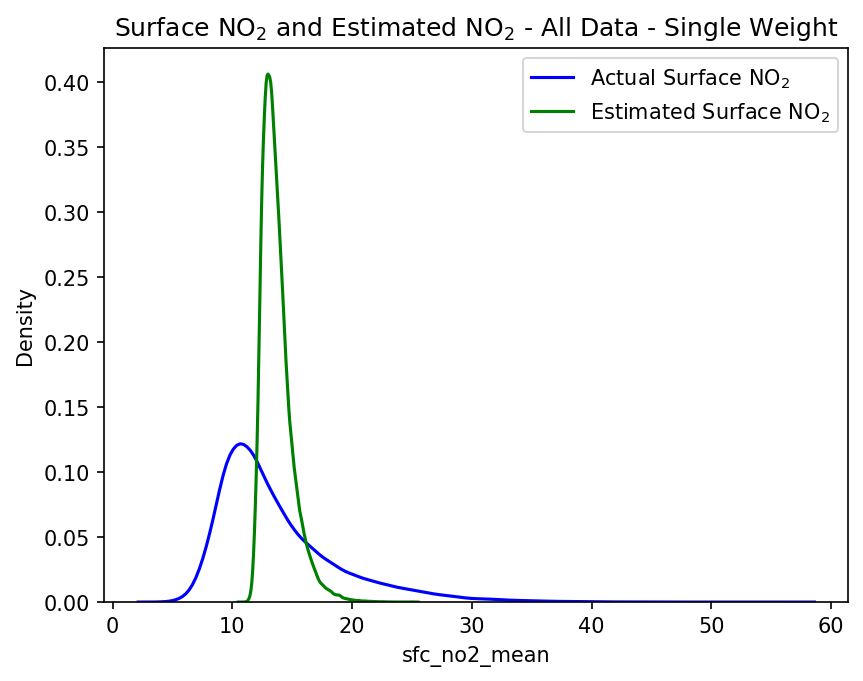

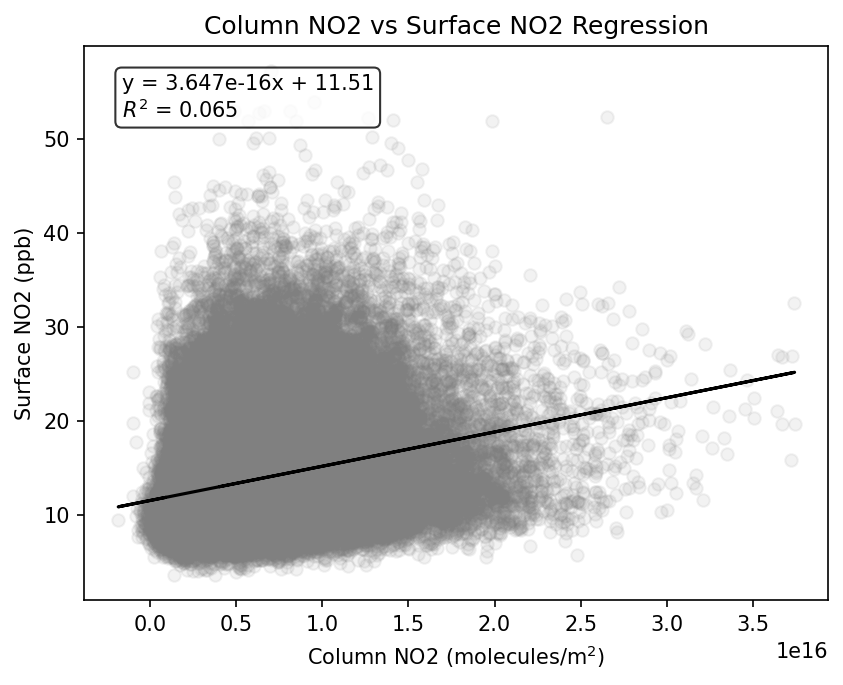

In [2]:
tempo_vals =  ct_hourly.column_no2_mean.to_dataframe().reset_index()
clarity_vals = ct_hourly.sfc_no2_mean.to_dataframe().reset_index()

both = clarity_vals.merge(tempo_vals, on=['latitude','longitude','time']).dropna()

x = both['column_no2_mean'].to_frame()
y = both['sfc_no2_mean'].to_frame()

model = linear_model.LinearRegression().fit(X=x, y=y)
score = model.score(X=x, y=y)

coef = float(np.ravel(model.coef_)[0])
rank = float(np.ravel(model.rank_)[0])
intercept = float(np.ravel(model.intercept_)[0])

print("Coef: ", coef)
print("Rank: ", rank)
print("Intercept: ", intercept)

print(score)

both['no2_estimate'] = both['column_no2_mean'].apply(lambda x: x*float(coef)+float(intercept))
print(both.head())

sns.kdeplot(both, x="sfc_no2_mean", color="blue", label='Actual Surface NO$_2$')
sns.kdeplot(both, x='no2_estimate', color="green", label='Estimated Surface NO$_2$')
plt.title("Surface NO$_2$ and Estimated NO$_2$ - All Data - Single Weight")
plt.legend()
savefig("kde-actual-and-estimated-single-weight.png")
plt.show()

eqn_text = f"y = {coef:.3e}x + {intercept:.2f}\n$R^2$ = {score:.3f}"

plt.scatter(x, y, color='grey', alpha=0.1)
plt.plot(x, model.predict(x),color='k' )
plt.title("Column NO2 vs Surface NO2 Regression")
plt.xlabel("Column NO2 (molecules/m$^2$)")
plt.ylabel("Surface NO2 (ppb)")
plt.annotate(eqn_text, xy=(0.05, 0.95), xycoords='axes fraction',
             ha='left', va='top', fontsize=10,
             bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

savefig("column-no2-vs-sfc-no2-alldata.png")
plt.show()




## Linear Regression - Time of Day - Single Weight


       hour   latitude  longitude  sfc_no2_mean  column_no2_mean
10071    11  41.650002 -87.550003     13.849752     5.809331e+15
10119    11  41.669998 -87.629997     18.629538     5.267957e+15
10120    11  41.669998 -87.610001     14.060144     5.336276e+15
10121    11  41.669998 -87.589996     17.227763     5.578089e+15
10122    11  41.669998 -87.570000     17.402100     5.591781e+15
Coef:  1.0573701625455932e-15
Rank:  1.0
Intercept:  8.111815190196364
0.13375856073768988
       hour   latitude  longitude  sfc_no2_mean  column_no2_mean  no2_estimate
10071    11  41.650002 -87.550003     13.849752     5.809331e+15     14.254428
10119    11  41.669998 -87.629997     18.629538     5.267957e+15     13.681995
10120    11  41.669998 -87.610001     14.060144     5.336276e+15     13.754234
10121    11  41.669998 -87.589996     17.227763     5.578089e+15     14.009920
10122    11  41.669998 -87.570000     17.402100     5.591781e+15     14.024398


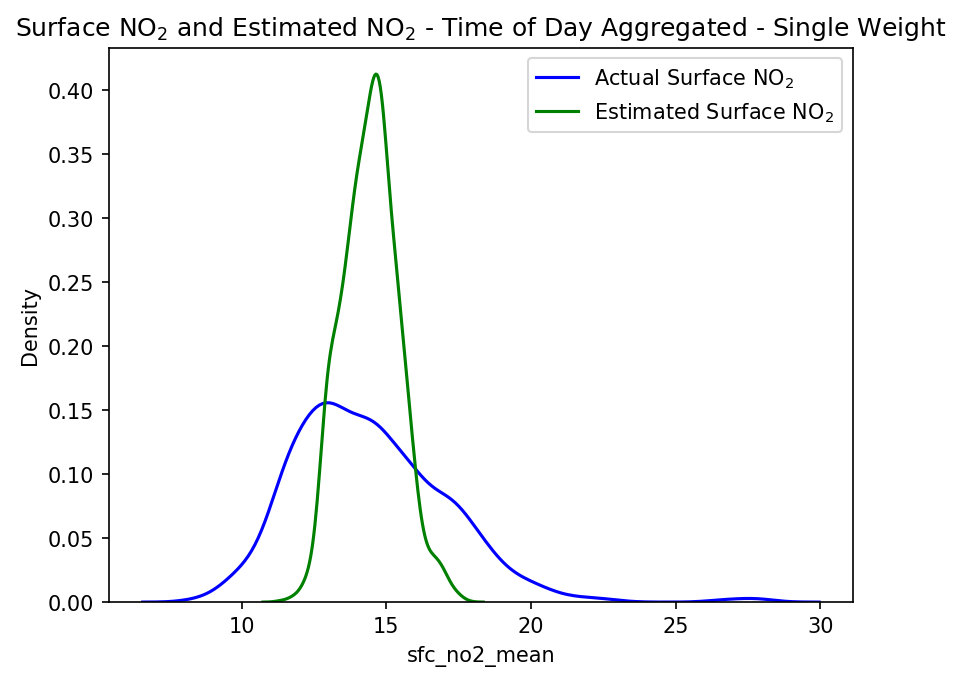

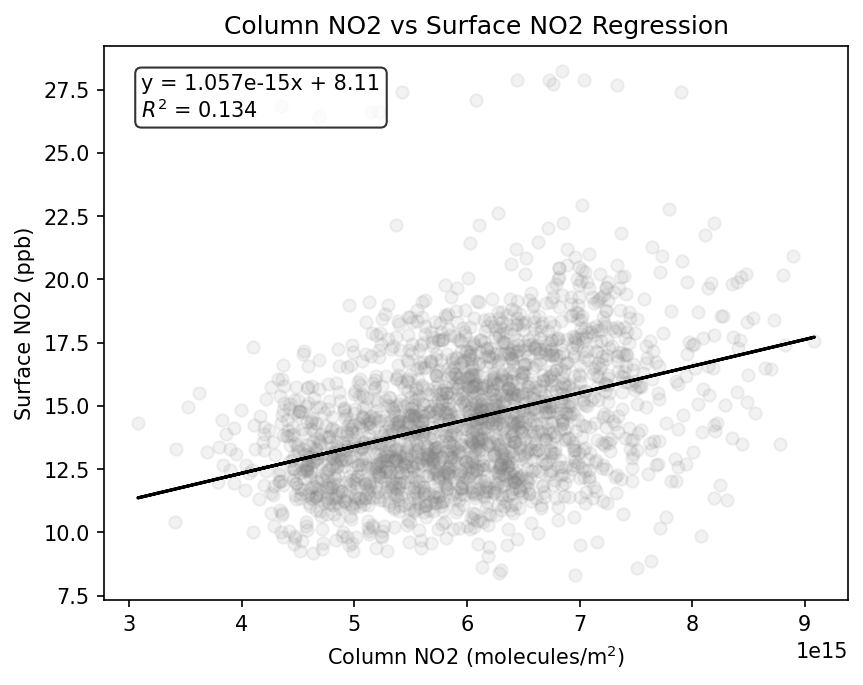

In [3]:
tempo_vals =  ct_diurnal.column_no2_mean.to_dataframe().reset_index()
clarity_vals = ct_diurnal.sfc_no2_mean.to_dataframe().reset_index()

both = clarity_vals.merge(tempo_vals, on=['latitude','longitude','hour']).dropna()
print(both.head())

x = both['column_no2_mean'].to_frame()
y = both['sfc_no2_mean'].to_frame()

model = linear_model.LinearRegression().fit(X=x, y=y)
score = model.score(X=x, y=y)

coef = float(np.ravel(model.coef_)[0])
rank = float(np.ravel(model.rank_)[0])
intercept = float(np.ravel(model.intercept_)[0])

print("Coef: ", coef)
print("Rank: ", rank)
print("Intercept: ", intercept)

print(score)

both['no2_estimate'] = both['column_no2_mean'].apply(lambda x: x*float(coef)+float(intercept))
print(both.head())

sns.kdeplot(both, x="sfc_no2_mean", color="blue", label='Actual Surface NO$_2$')
sns.kdeplot(both, x='no2_estimate', color="green", label='Estimated Surface NO$_2$')
plt.title("Surface NO$_2$ and Estimated NO$_2$ - Time of Day Aggregated - Single Weight")
plt.legend()
savefig("kde-actual-and-estimated-tod-single-weight.png")
plt.show()


eqn_text = f"y = {coef:.3e}x + {intercept:.2f}\n$R^2$ = {score:.3f}"

plt.scatter(x, y, color='grey', alpha=0.1)
plt.plot(x, model.predict(x),color='k' )
plt.title("Column NO2 vs Surface NO2 Regression")
plt.xlabel("Column NO2 (molecules/m$^2$)")
plt.ylabel("Surface NO2 (ppb)")
plt.annotate(eqn_text, xy=(0.05, 0.95), xycoords='axes fraction',
             ha='left', va='top', fontsize=10,
             bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
savefig("column-no2-vs-sfc-no2-regression-tod-single-weight.png")
plt.show()


## Linear Regression - Time of Day - Hourly Weights

    hour          coef  intercept     score
0     11  8.037608e-16  11.944953  0.141404
1     12  1.328250e-15   9.005151  0.134943
2     13  1.193698e-15   8.750858  0.111381
3     14  1.052220e-15   8.368581  0.081068
4     15  1.073252e-15   6.895271  0.109347
5     16  8.293040e-16   7.917001  0.064404
6     17  7.456288e-16   8.387536  0.055028
7     18  1.166441e-15   6.108015  0.090060
8     19  1.201530e-15   6.212961  0.075708
9     20  1.242921e-15   6.501273  0.114813
10    21  8.371338e-16   8.940245  0.071328
11    22  1.013401e-15   8.458442  0.096267
12    23  9.935751e-16   9.811594  0.115722
   hour   latitude  longitude  sfc_no2_mean  column_no2_mean          coef  \
0    11  41.650002 -87.550003     13.849752     5.809331e+15  8.037608e-16   
1    11  41.669998 -87.629997     18.629538     5.267957e+15  8.037608e-16   
2    11  41.669998 -87.610001     14.060144     5.336276e+15  8.037608e-16   
3    11  41.669998 -87.589996     17.227763     5.578089e+15  8.037608e-

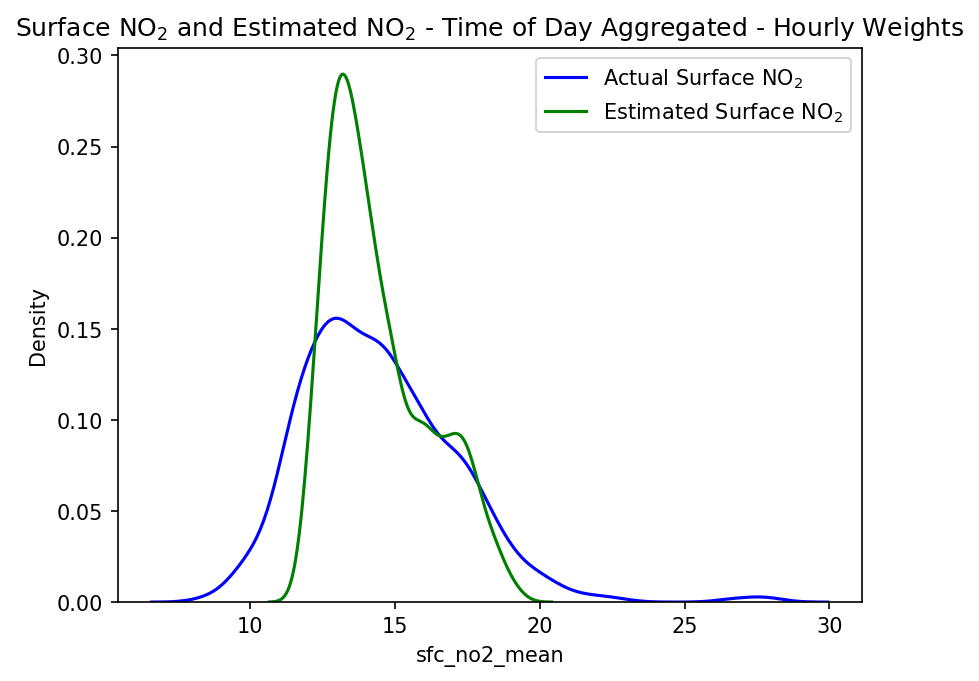

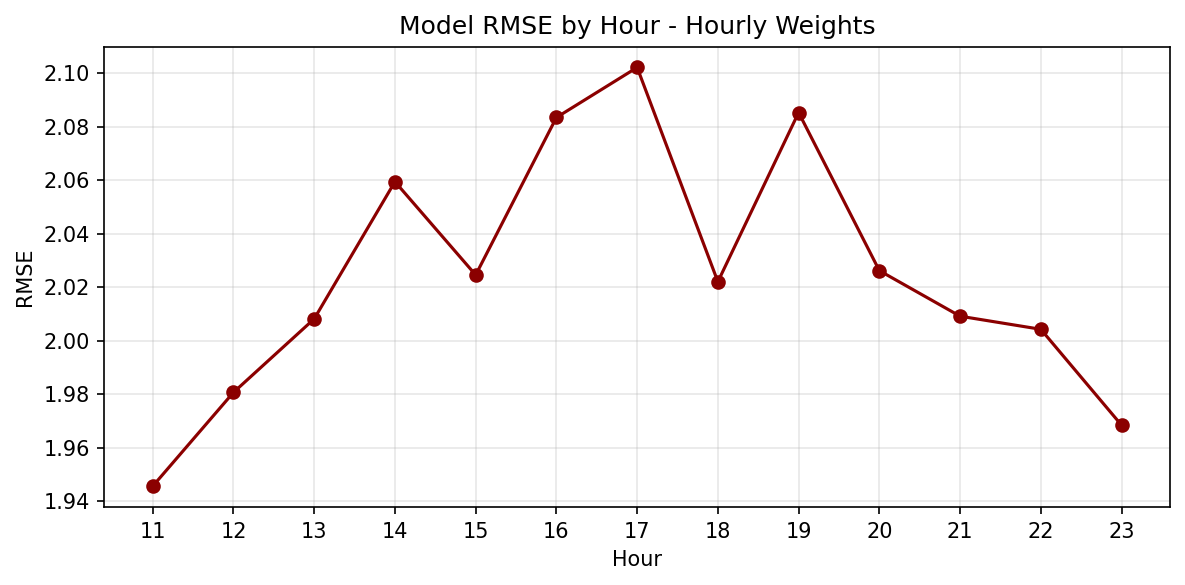

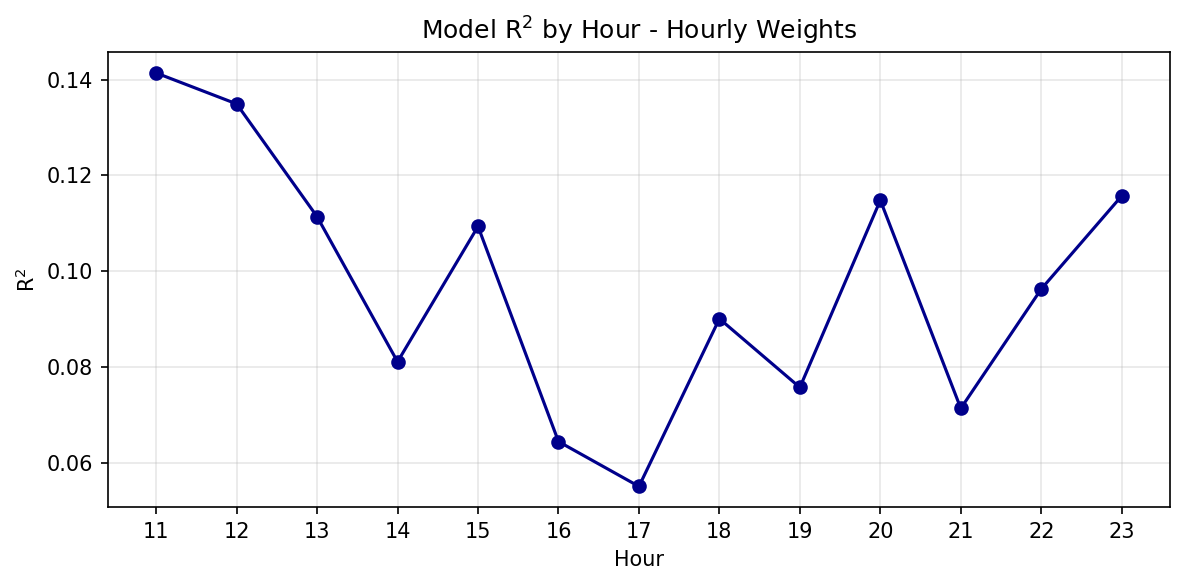

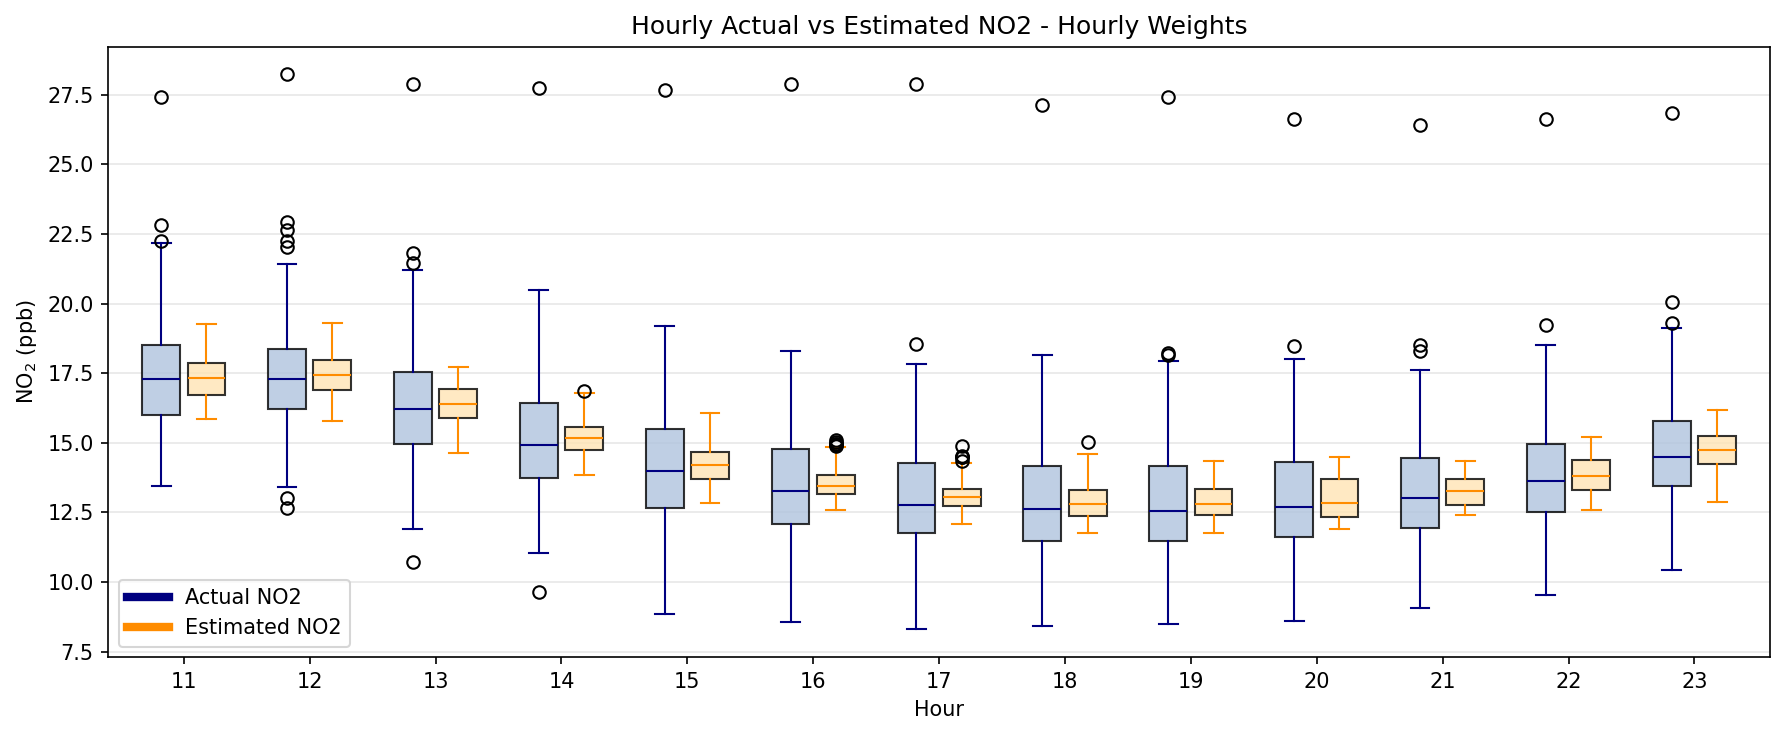

In [4]:
tempo_vals =  ct_diurnal.column_no2_mean.to_dataframe().reset_index()
clarity_vals = ct_diurnal.sfc_no2_mean.to_dataframe().reset_index()

both = clarity_vals.merge(tempo_vals, on=['latitude', 'longitude', 'hour']).dropna()

model_rows = []
for hour in sorted(both['hour'].dropna().unique()):
    x_hour = both.loc[both['hour'] == hour, ['column_no2_mean']]
    y_hour = both.loc[both['hour'] == hour, ['sfc_no2_mean']]

    if len(x_hour) < 2:
        continue

    hour_model = linear_model.LinearRegression().fit(X=x_hour, y=y_hour)
    model_rows.append({
        'hour': hour,
        'coef': float(hour_model.coef_.ravel()[0]),
        'intercept': float(hour_model.intercept_.ravel()[0]),
        'score': hour_model.score(X=x_hour, y=y_hour)
    })

model_vals = pd.DataFrame(model_rows)
print(model_vals)

both = both.merge(model_vals, on='hour', how='left')
both['no2_estimate'] = both['column_no2_mean'] * both['coef'] + both['intercept']

hour_rmse = both.groupby('hour').apply(
    lambda group: rmse(group['sfc_no2_mean'], group['no2_estimate'])
)
both['rmse'] = both['hour'].map(hour_rmse)

print(both.head())

sns.kdeplot(both, x="sfc_no2_mean", color="blue", label='Actual Surface NO$_2$')
sns.kdeplot(both, x='no2_estimate', color="green", label='Estimated Surface NO$_2$')
plt.title("Surface NO$_2$ and Estimated NO$_2$ - Time of Day Aggregated - Hourly Weights")
plt.legend()
savefig("kde-actual-and-estimated-tod-hourly-weight.png")
plt.show()

hour_rmse_df = hour_rmse.reset_index()
hour_rmse_df.columns = ['hour', 'rmse']

plt.figure(figsize=(8, 4))
plt.plot(hour_rmse_df['hour'], hour_rmse_df['rmse'], marker='o', color='darkred')
plt.xticks(hour_rmse_df['hour'])
plt.xlabel('Hour')
plt.ylabel('RMSE')
plt.title('Model RMSE by Hour - Hourly Weights')
plt.grid(True, alpha=0.3)
plt.tight_layout()
savefig("hourly-weights-rmse.png")
plt.show()


plt.figure(figsize=(8, 4))
plt.plot(model_vals['hour'], model_vals['score'], marker='o', color='darkblue')
plt.xticks(model_vals['hour'])
plt.xlabel('Hour')
plt.ylabel('R$^2$')
plt.title('Model R$^2$ by Hour - Hourly Weights')
plt.grid(True, alpha=0.3)
plt.tight_layout()
savefig("hourly-weights-r2.png")
plt.show()


hour_dat = both[['hour']].drop_duplicates().sort_values('hour').reset_index(drop=True)

hours = [int(hour) for hour in hour_dat['hour'].to_list()]
actual_by_hour = [both.loc[both['hour'] == hour, 'sfc_no2_mean'].dropna() for hour in hours]
estimated_by_hour = [both.loc[both['hour'] == hour, 'no2_estimate'].dropna() for hour in hours]

fig, ax = plt.subplots(figsize=(12, 5))

positions_actual = [hour - 0.18 for hour in hours]
positions_estimated = [hour + 0.18 for hour in hours]

ax.boxplot(
    actual_by_hour,
    positions=positions_actual,
    widths=0.3,
    patch_artist=True,
    boxprops=dict(facecolor='lightsteelblue', alpha=0.8),
    medianprops=dict(color='navy'),
    whiskerprops=dict(color='navy'),
    capprops=dict(color='navy'),
)
ax.boxplot(
    estimated_by_hour,
    positions=positions_estimated,
    widths=0.3,
    patch_artist=True,
    boxprops=dict(facecolor='moccasin', alpha=0.8),
    medianprops=dict(color='darkorange'),
    whiskerprops=dict(color='darkorange'),
    capprops=dict(color='darkorange'),
)

ax.set_xticks(hours)
ax.set_xticklabels(hours)
ax.set_xlim(min(hours) - 0.6, max(hours) + 0.6)
ax.set_xlabel('Hour')
ax.set_ylabel('NO$_2$ (ppb)')
ax.set_title('Hourly Actual vs Estimated NO2 - Hourly Weights')
ax.grid(True, axis='y', alpha=0.3)

actual_patch = plt.Line2D([0], [0], color='navy', lw=4, label='Actual NO2')
estimated_patch = plt.Line2D([0], [0], color='darkorange', lw=4, label='Estimated NO2')
ax.legend(handles=[actual_patch, estimated_patch])

plt.tight_layout()

savefig("boxplots-actual-vs-estimated-no2-hourly-weights.png")
plt.show()

## Linear Regression - Time of Day - Hourly Weights - Month Filtering

This section is run over data with months Dec 2025, Jan 2026, and Feb 2026 filtered out due to the significant number of missing values over the dataset. These data are merged and filtered using the clarity-tempo-aggregation.ipynb notebook.

    hour          coef  intercept     score
0     11  8.634567e-16  11.440248  0.158721
1     12  1.349782e-15   8.661355  0.137919
2     13  1.158218e-15   8.580919  0.103057
3     14  9.777385e-16   7.987794  0.086830
4     15  9.669113e-16   6.838169  0.104841
5     16  6.378111e-16   8.570400  0.051325
6     17  6.322494e-16   8.477799  0.055091
7     18  1.016827e-15   6.591892  0.095205
8     19  9.909450e-16   7.042665  0.089797
9     20  9.036758e-16   7.816207  0.101874
10    21  7.876261e-16   8.658241  0.076357
11    22  1.008341e-15   7.795988  0.097884
12    23  9.915717e-16   9.100674  0.117669
   hour   latitude  longitude  sfc_no2_mean  column_no2_mean          coef  \
0    11  41.650002 -87.550003     13.995153     5.809331e+15  8.634567e-16   
1    11  41.669998 -87.629997     18.741364     5.267957e+15  8.634567e-16   
2    11  41.669998 -87.610001     13.871562     5.336276e+15  8.634567e-16   
3    11  41.669998 -87.589996     16.882560     5.578089e+15  8.634567e-

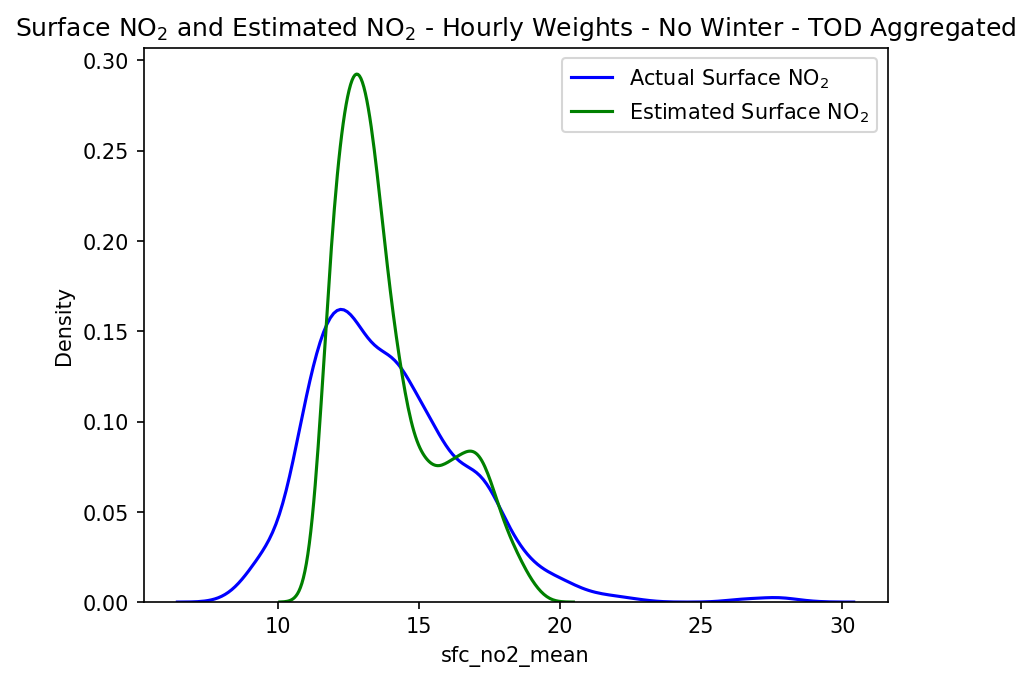

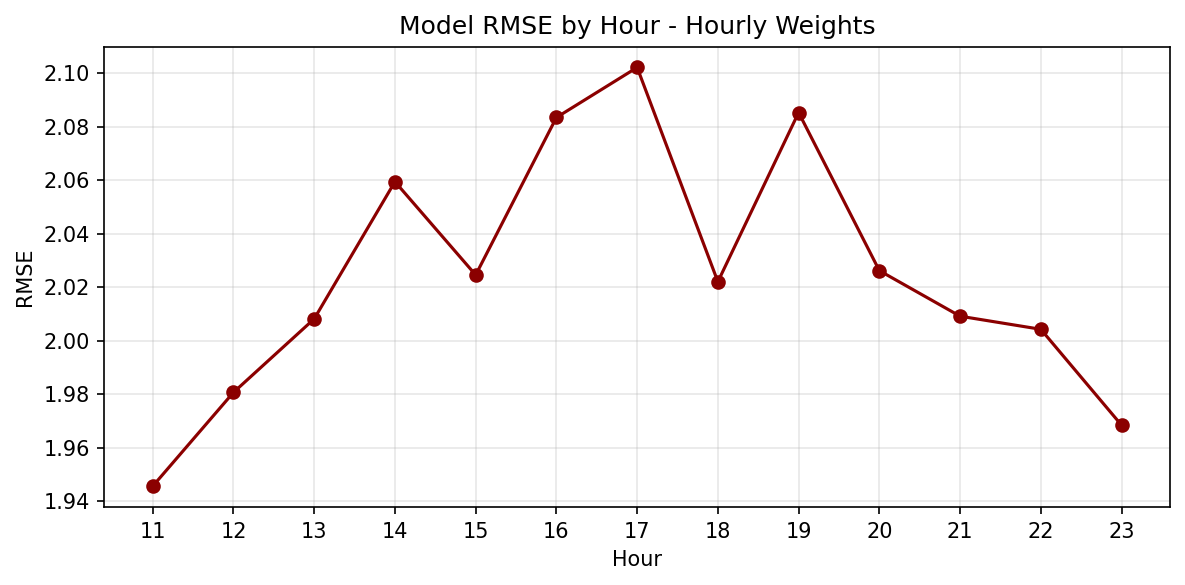

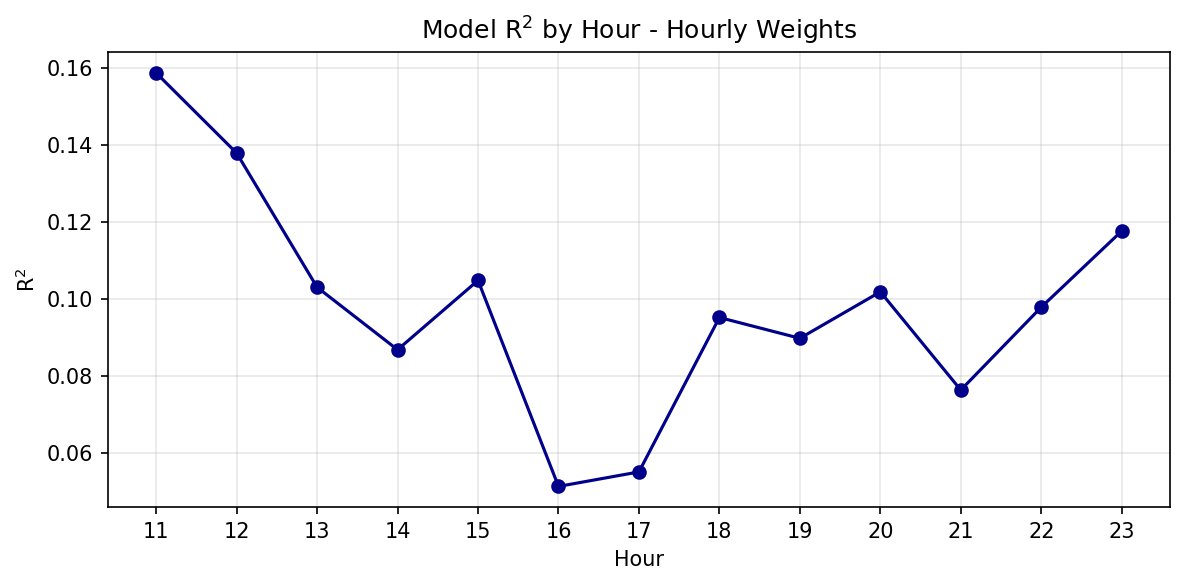

In [5]:


clarity_vals = ct_nowinter.sfc_no2_mean.to_dataframe().reset_index()
tempo_vals =  ct_nowinter.column_no2_mean.to_dataframe().reset_index()

both = clarity_vals.merge(tempo_vals, on=['latitude', 'longitude', 'hour']).dropna()

model_rows = []
for hour in sorted(both['hour'].dropna().unique()):
    x_hour = both.loc[both['hour'] == hour, ['column_no2_mean']]
    y_hour = both.loc[both['hour'] == hour, ['sfc_no2_mean']]

    if len(x_hour) < 2:
        continue

    hour_model = linear_model.LinearRegression().fit(X=x_hour, y=y_hour)
    model_rows.append({
        'hour': hour,
        'coef': float(hour_model.coef_.ravel()[0]),
        'intercept': float(hour_model.intercept_.ravel()[0]),
        'score': hour_model.score(X=x_hour, y=y_hour)
    })

model_vals = pd.DataFrame(model_rows)
print(model_vals)

both = both.merge(model_vals, on='hour', how='left')
both['no2_estimate'] = both['column_no2_mean'] * both['coef'] + both['intercept']

hour_rmse = both.groupby('hour').apply(
    lambda group: rmse(group['sfc_no2_mean'], group['no2_estimate'])
)

# spatial_rmse = both.groupby('hour').apply(
#     lambda group: rmse(group['sfc_no2_mean'], group['no2_estimate'])
# )

both['rmse'] = both['hour'].map(hour_rmse)

print(both.head())

sns.kdeplot(both, x="sfc_no2_mean", color="blue", label='Actual Surface NO$_2$')
sns.kdeplot(both, x='no2_estimate', color="green", label='Estimated Surface NO$_2$')
plt.title("Surface NO$_2$ and Estimated NO$_2$ - Hourly Weights - No Winter - TOD Aggregated")
plt.legend()
savefig("kde-actual-and-estimated-tod-hourly-weights-nowinter.png")
plt.show()


plt.figure(figsize=(8, 4))
plt.plot(hour_rmse_df['hour'], hour_rmse_df['rmse'], marker='o', color='darkred')
plt.xticks(hour_rmse_df['hour'])
plt.xlabel('Hour')
plt.ylabel('RMSE')
plt.title('Model RMSE by Hour - Hourly Weights')
plt.grid(True, alpha=0.3)
plt.tight_layout()
savefig("hourly-weights-nowinter-rmse.png")
plt.show()


plt.figure(figsize=(8, 4))
plt.plot(model_vals['hour'], model_vals['score'], marker='o', color='darkblue')
plt.xticks(model_vals['hour'])
plt.xlabel('Hour')
plt.ylabel('R$^2$')
plt.title('Model R$^2$ by Hour - Hourly Weights')
plt.grid(True, alpha=0.3)
plt.tight_layout()
savefig("hourly-weights-nowinter-r2.png")
plt.show()

# Random Plotting


#### Boxplot of Actual vs Estimated NO2

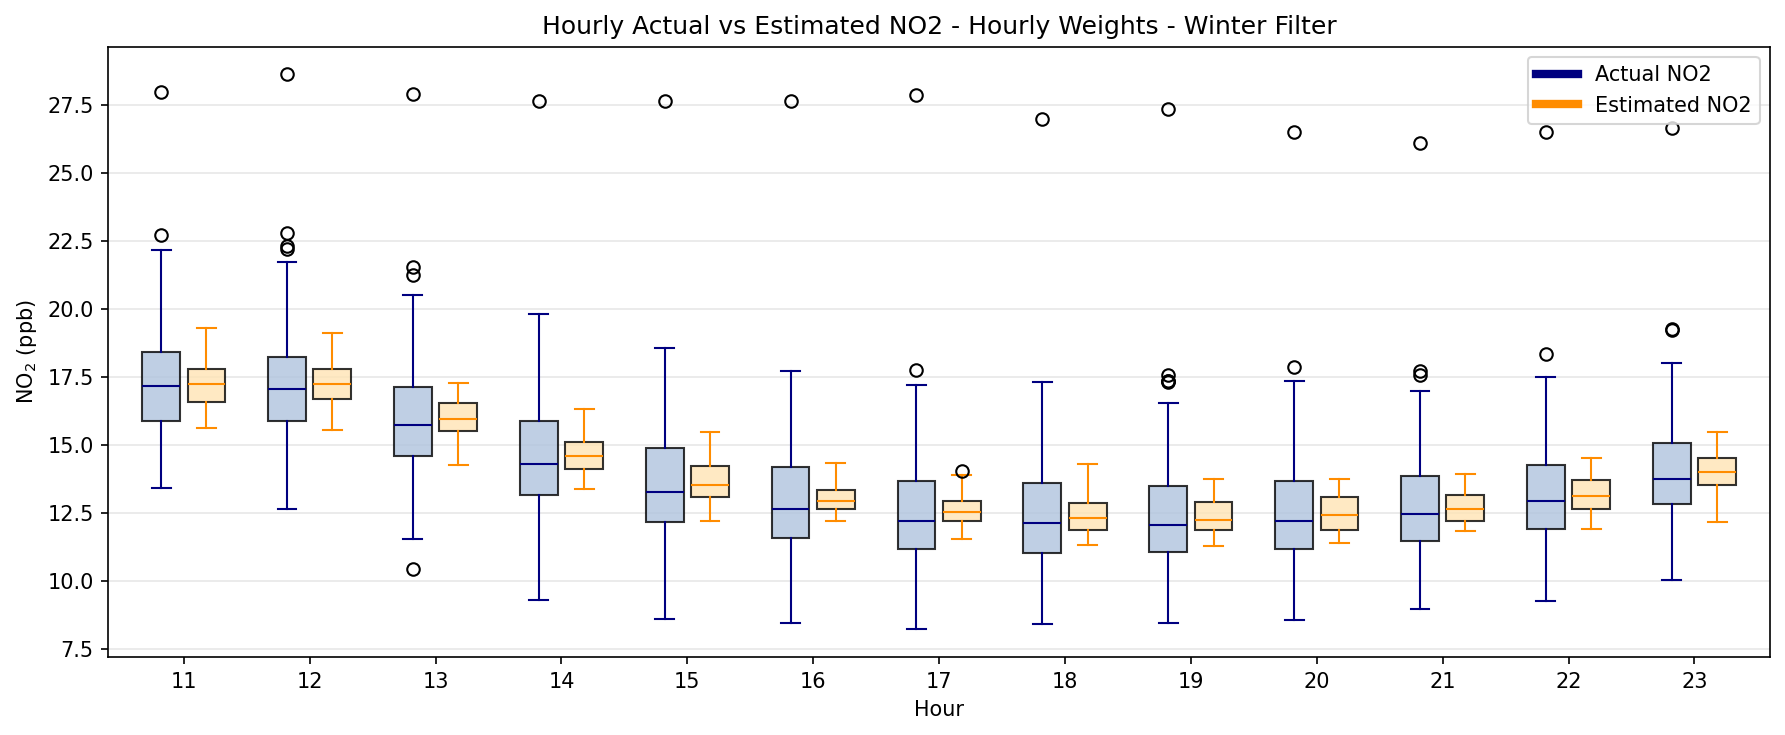

In [6]:
hour_dat = both[['hour']].drop_duplicates().sort_values('hour').reset_index(drop=True)

hours = [int(hour) for hour in hour_dat['hour'].to_list()]
actual_by_hour = [both.loc[both['hour'] == hour, 'sfc_no2_mean'].dropna() for hour in hours]
estimated_by_hour = [both.loc[both['hour'] == hour, 'no2_estimate'].dropna() for hour in hours]

fig, ax = plt.subplots(figsize=(12, 5))

positions_actual = [hour - 0.18 for hour in hours]
positions_estimated = [hour + 0.18 for hour in hours]

ax.boxplot(
    actual_by_hour,
    positions=positions_actual,
    widths=0.3,
    patch_artist=True,
    boxprops=dict(facecolor='lightsteelblue', alpha=0.8),
    medianprops=dict(color='navy'),
    whiskerprops=dict(color='navy'),
    capprops=dict(color='navy'),
)
ax.boxplot(
    estimated_by_hour,
    positions=positions_estimated,
    widths=0.3,
    patch_artist=True,
    boxprops=dict(facecolor='moccasin', alpha=0.8),
    medianprops=dict(color='darkorange'),
    whiskerprops=dict(color='darkorange'),
    capprops=dict(color='darkorange'),
)

ax.set_xticks(hours)
ax.set_xticklabels(hours)
ax.set_xlim(min(hours) - 0.6, max(hours) + 0.6)
ax.set_xlabel('Hour')
ax.set_ylabel('NO$_2$ (ppb)')
ax.set_title('Hourly Actual vs Estimated NO2 - Hourly Weights - Winter Filter')
ax.grid(True, axis='y', alpha=0.3)

actual_patch = plt.Line2D([0], [0], color='navy', lw=4, label='Actual NO2')
estimated_patch = plt.Line2D([0], [0], color='darkorange', lw=4, label='Estimated NO2')
ax.legend(handles=[actual_patch, estimated_patch])

plt.tight_layout()

savefig("boxplots-actual-vs-estimated-no2-hourly-weights-nowinter.png")
plt.show()

#### Boxplot of tempo values by hour

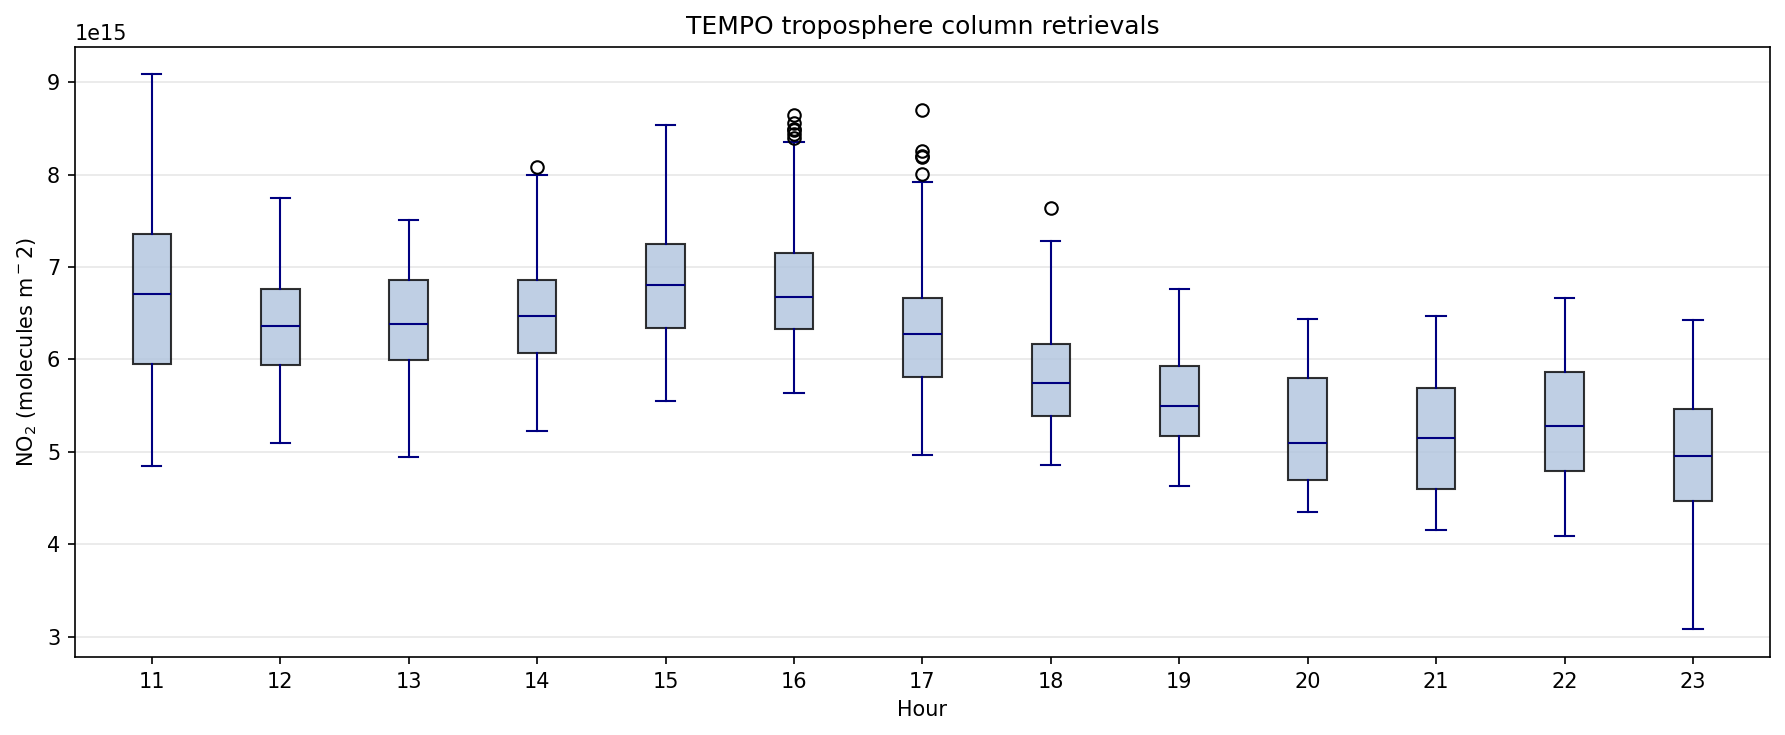

In [7]:
tempo_vals =  ct_diurnal.column_no2_mean.to_dataframe().reset_index()
clarity_vals = ct_diurnal.sfc_no2_mean.to_dataframe().reset_index()

both = clarity_vals.merge(tempo_vals, on=['latitude', 'longitude', 'hour']).dropna()

hour_dat = both[['hour']].drop_duplicates().sort_values('hour').reset_index(drop=True)
hours = [int(hour) for hour in hour_dat['hour'].to_list()]

fig, ax = plt.subplots(figsize=(12, 5))

# hours = [int(hour) for hour in tempo_vals['hour'].to_list()]
actual_by_hour = [both.loc[both['hour'] == hour, 'column_no2_mean'].dropna() for hour in hours]
positions_actual = [hour for hour in hours]


ax.boxplot(
    actual_by_hour,
    positions=positions_actual,
    widths=0.3,
    patch_artist=True,
    boxprops=dict(facecolor='lightsteelblue', alpha=0.8),
    medianprops=dict(color='navy'),
    whiskerprops=dict(color='navy'),
    capprops=dict(color='navy'),
)

ax.set_xticks(hours)
ax.set_xticklabels(hours)
ax.set_xlim(min(hours) - 0.6, max(hours) + 0.6)
ax.set_xlabel('Hour')
ax.set_ylabel('NO$_2$ (molecules m$^-2$)')
ax.set_title('TEMPO troposphere column retrievals')
ax.grid(True, axis='y', alpha=0.3)

plt.tight_layout()

savefig("boxplot-tempo-mean-vals.png")
plt.show()

       hour   latitude  longitude  sfc_no2_mean  column_no2_mean  \
10071    11  41.650002 -87.550003     13.849752     5.809331e+15   
10119    11  41.669998 -87.629997     18.629538     5.267957e+15   
10120    11  41.669998 -87.610001     14.060144     5.336276e+15   
10121    11  41.669998 -87.589996     17.227763     5.578089e+15   
10122    11  41.669998 -87.570000     17.402100     5.591781e+15   

               coef  intercept     score  no2_estimate  
10071  8.634567e-16  11.440248  0.158721     16.456353  
10119  8.634567e-16  11.440248  0.158721     15.988900  
10120  8.634567e-16  11.440248  0.158721     16.047891  
10121  8.634567e-16  11.440248  0.158721     16.256686  
10122  8.634567e-16  11.440248  0.158721     16.268508  


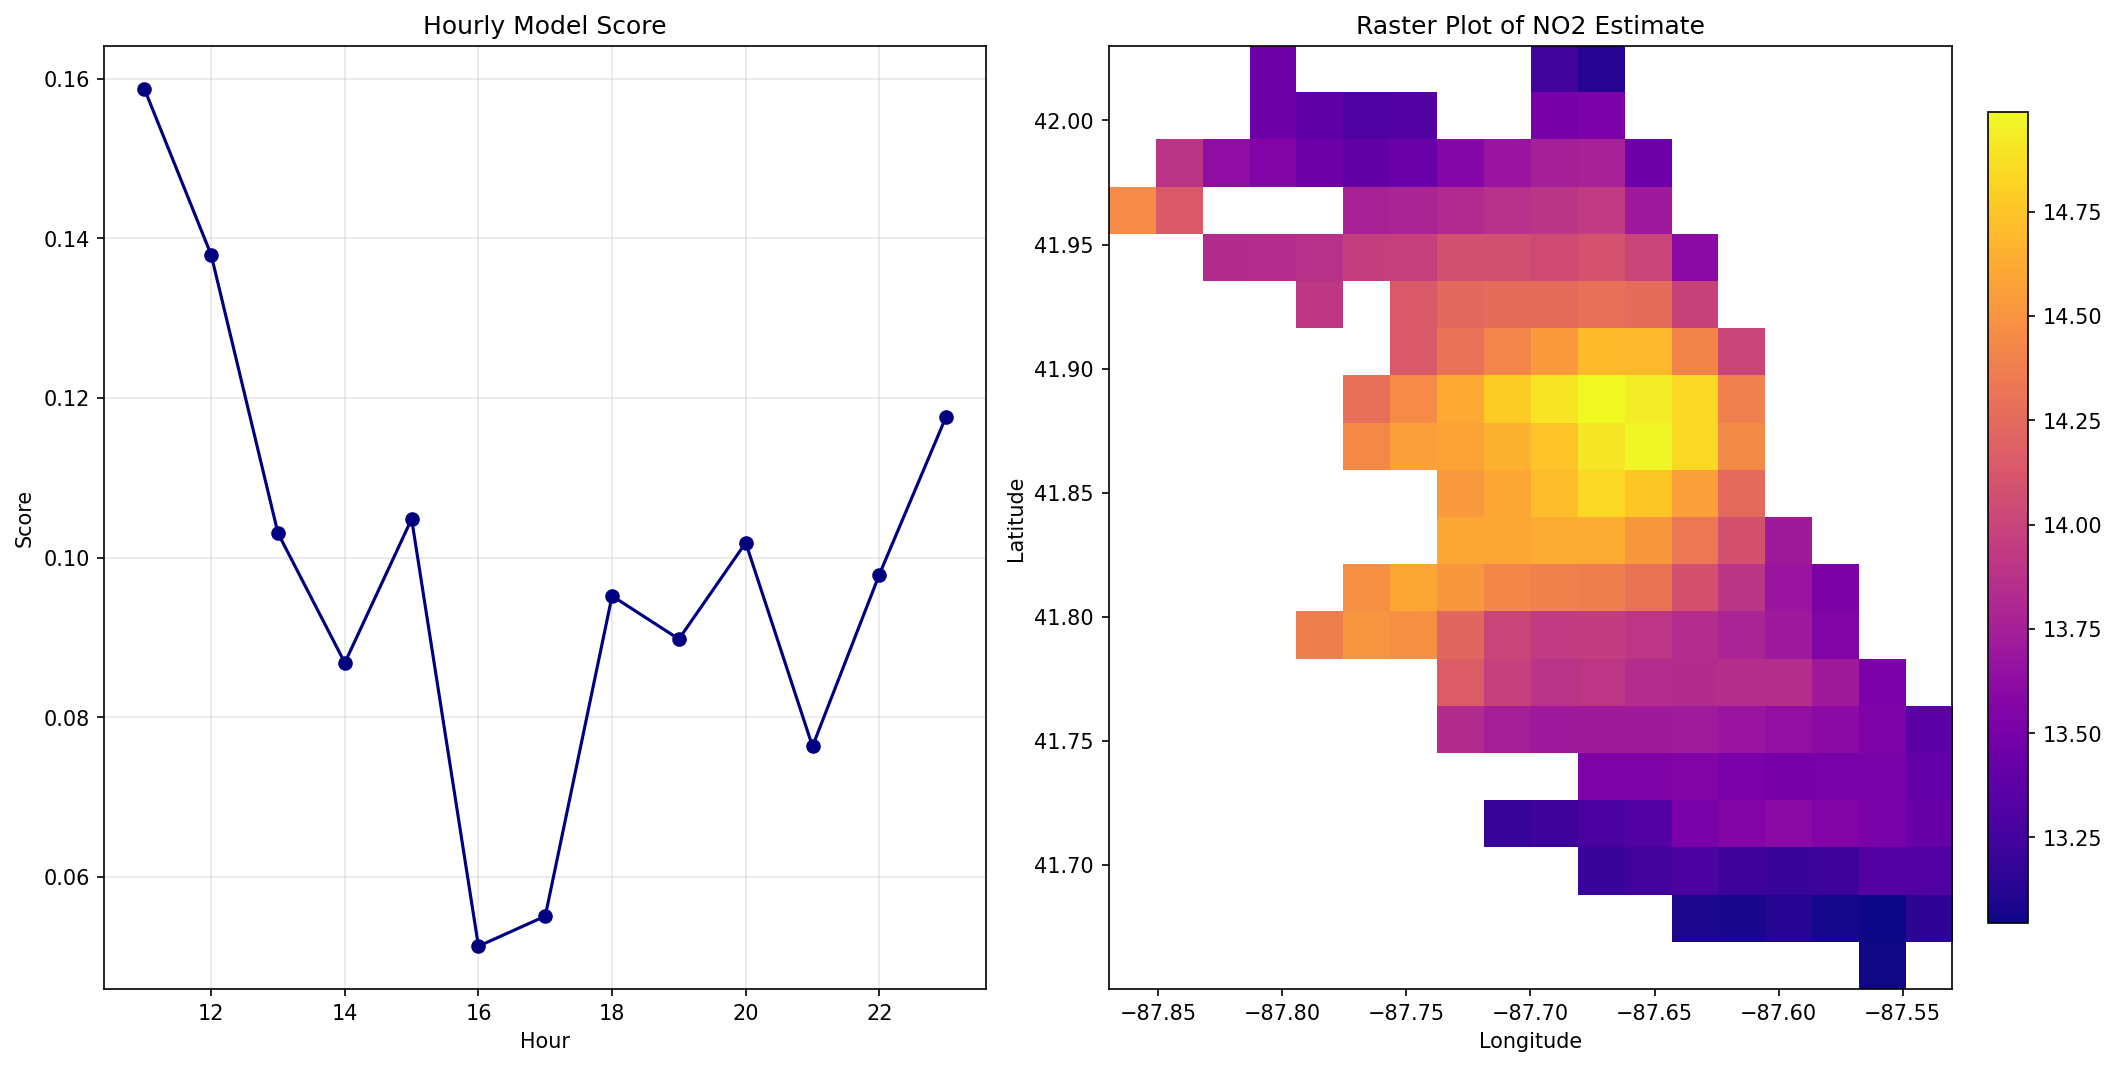

In [8]:

# Attach the hourly model results before computing the estimate and plotting
hour_lookup = model_vals.set_index('hour')
both['coef'] = both['hour'].map(hour_lookup['coef'])
both['intercept'] = both['hour'].map(hour_lookup['intercept'])
both['score'] = both['hour'].map(hour_lookup['score'])
both['no2_estimate'] = both['column_no2_mean'] * both['coef'] + both['intercept']
print(both.head())

# Build gridded rasters from the lat/lon cells in the notebook
score_grid = both.pivot_table(
    index='latitude',
    columns='longitude',
    values='score',
    aggfunc='mean',
).sort_index(axis=0).sort_index(axis=1)
estimate_grid = both.pivot_table(
    index='latitude',
    columns='longitude',
    values='no2_estimate',
    aggfunc='mean',
).sort_index(axis=0).sort_index(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(14, 7), constrained_layout=True)

hourly_scores = model_vals.sort_values('hour')
axes[0].plot(hourly_scores['hour'], hourly_scores['score'], marker='o', color='navy')
axes[0].set_title('Hourly Model Score')
axes[0].set_xlabel('Hour')
axes[0].set_ylabel('Score')
axes[0].grid(True, alpha=0.3)

estimate_image = axes[1].imshow(
    estimate_grid.to_numpy(),
    extent=[estimate_grid.columns.min(), estimate_grid.columns.max(), estimate_grid.index.min(), estimate_grid.index.max()],
    origin='lower',
    cmap='plasma',
    aspect='equal',
)
axes[1].set_title('Raster Plot of NO2 Estimate')
axes[1].set_xlabel('Longitude')
axes[1].set_ylabel('Latitude')
fig.colorbar(estimate_image, ax=axes[1], fraction=0.046, pad=0.04)

plt.show()